In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3,3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3,3), padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(64, (3,3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3,3), padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(128, (3,3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()   # <-- screenshot this (Output 1)

history = model.fit(x_train, y_train, epochs=30, batch_size=64,
                    validation_split=0.1)

test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test accuracy:", test_acc)   # <-- screenshot this (Output 2)

model.save("cifar10_cnn.keras")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1004s 6us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 403,882 (1.54 MB)

 Trainable params: 403,434 (1.54 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 43s 35ms/step - accuracy: 0.3188 - loss: 1.8529 - val_accuracy: 0.4402 - val_loss: 1.4980
Epoch 2/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4656 - loss: 1.4626 - val_accuracy: 0.5842 - val_loss: 1.1492
Epoch 3/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5612 - loss: 1.2361 - val_accuracy: 0.6416 - val_loss: 1.0222
Epoch 4/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6156 - loss: 1.1046 - val_accuracy: 0.6760 - val_loss: 0.9105
Epoch 5/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6510 - loss: 1.0063 - val_accuracy: 0.6478 - val_loss: 1.0128
Epoch 6/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6811 - loss: 0.9346 - val_accuracy: 0.7102 - val_loss: 0.8302
Epoch 7/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7045 - loss: 0.8651 - val_accuracy: 0.7372 - val_loss: 0.7913
Epoch 8/30
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7198 - loss: 0.8181 - val_accuracy: 

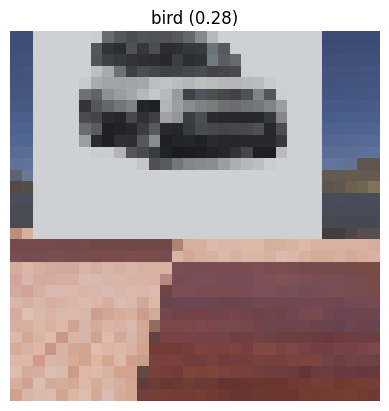

  bird: 27.57%
  cat: 26.16%
  dog: 20.48%


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

def predict_image(path):
    img = image.load_img(path, target_size=(32, 32))
    arr = np.expand_dims(np.array(img) / 255.0, axis=0)
    probs = model.predict(arr, verbose=0)[0]
    top3 = np.argsort(probs)[::-1][:3]
    plt.imshow(img); plt.axis('off')
    plt.title(f"{class_names[top3[0]]} ({probs[top3[0]]:.2f})")
    plt.show()
    for i in top3:
        print(f"  {class_names[i]}: {probs[i]:.2%}")

predict_image("frame.png")

In [5]:
# ===== SETUP CELL: run this first, every time =====
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Load the trained model only if it isn't already in memory
try:
    model
    print("Model already in memory.")
except NameError:
    model = tf.keras.models.load_model("cifar10_cnn.keras")
    print("Model loaded from cifar10_cnn.keras")


def predict_image(path, true_class=None, crop_box=None, show=True):
    """Classify one image.
    path:       image file (jpg, png, webp...), converted to RGB automatically
    true_class: optional, printed so you can compare
    crop_box:   optional (left, top, right, bottom) to crop before classifying
    """
    img = Image.open(path).convert("RGB")
    if crop_box:
        img = img.crop(crop_box)
    small = img.resize((32, 32))
    arr = np.expand_dims(np.array(small) / 255.0, axis=0)
    probs = model.predict(arr, verbose=0)[0]
    top3 = np.argsort(probs)[::-1][:3]
    pred = class_names[top3[0]]

    if show:
        plt.imshow(img); plt.axis('off')
        title = f"{pred} ({probs[top3[0]]:.2f})"
        if true_class:
            title += f" | true: {true_class}"
        plt.title(title)
        plt.show()
    print(f"File: {path}" + (f" | True: {true_class}" if true_class else ""))
    for i in top3:
        print(f"  {class_names[i]}: {probs[i]:.2%}")
    if true_class:
        print("  Correct!" if pred == true_class else "  Wrong.")
    print("-" * 30)
    return pred, float(probs[top3[0]])


def predict_many(items):
    """items = [(file, true_class), ...]  -> prints a results table at the end"""
    rows = []
    for path, true_class in items:
        pred, conf = predict_image(path, true_class)
        rows.append((path, true_class, pred, conf, pred == true_class))
    print(f"{'Image':<20}{'True':<12}{'Predicted':<12}{'Conf':<8}Correct")
    for p, t, pr, c, ok in rows:
        print(f"{p:<20}{t:<12}{pr:<12}{c:<8.2f}{ok}")


print("Setup done. Ready to test.")

Model already in memory.
Setup done. Ready to test.


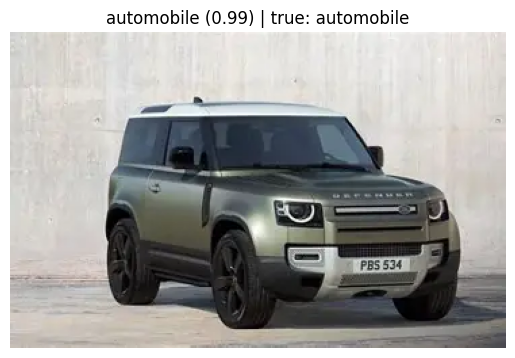

File: car.webp | True: automobile
  automobile: 98.82%
  truck: 1.04%
  ship: 0.11%
  Correct!
------------------------------


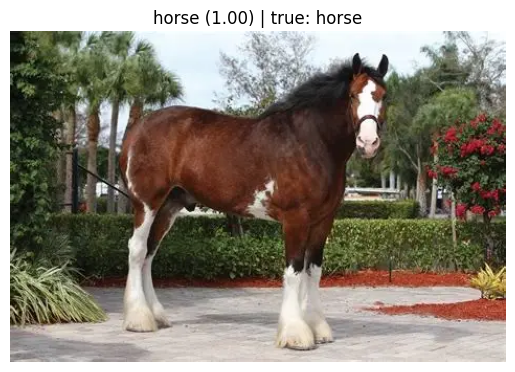

File: horse.webp | True: horse
  horse: 99.57%
  truck: 0.19%
  deer: 0.10%
  Correct!
------------------------------


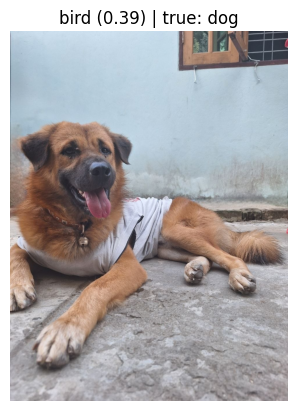

File: dog.jpg | True: dog
  bird: 39.47%
  cat: 33.61%
  dog: 18.09%
  Wrong.
------------------------------
Image               True        Predicted   Conf    Correct
car.webp            automobile  automobile  0.99    True
horse.webp          horse       horse       1.00    True
dog.jpg             dog         bird        0.39    False


In [6]:
predict_many([
    ("car.webp", "automobile"),
    ("horse.webp", "horse"),
    ("dog.jpg", "dog"),
])

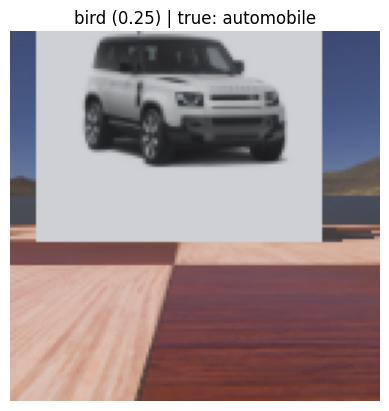

File: frame_car_60cm.png | True: automobile
  bird: 25.49%
  cat: 24.01%
  airplane: 22.64%
  Wrong.
------------------------------


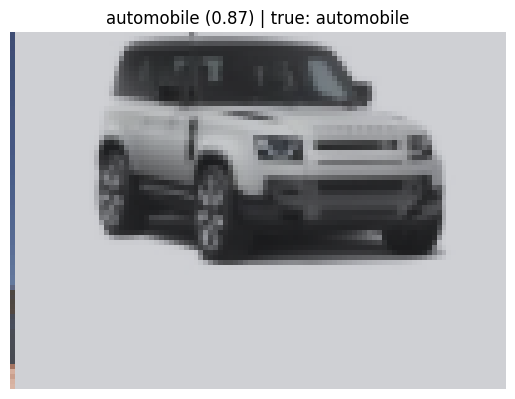

File: frame_car_60cm.png | True: automobile
  automobile: 86.56%
  truck: 13.11%
  ship: 0.33%
  Correct!
------------------------------


('automobile', 0.865588903427124)

In [7]:
predict_image("frame_car_60cm.png", true_class="automobile")
predict_image("frame_car_60cm.png", true_class="automobile", crop_box=(8, 0, 108, 72))